In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

In [ ]:
proj_dir="/content/drive/MyDrive/MLP_PROJECT_ONE"
print(os.path.join(proj_dir,"checkpoints"),":",os.path.isdir(os.path.join(proj_dir,"checkpoints")))
print(os.path.join(proj_dir,"exports"),":",os.path.isdir(os.path.join(proj_dir,"exports")))
print(os.path.join(proj_dir,"logs"),":",os.path.isdir(os.path.join(proj_dir,"logs")))
print(os.path.join(proj_dir,"notebooks"),":",os.path.isdir(os.path.join(proj_dir,"notebooks")))
print(os.path.join(proj_dir,"results"),":",os.path.isdir(os.path.join(proj_dir,"results")))

/content/drive/MyDrive/MLP_PROJECT_ONE/checkpoints : True
/content/drive/MyDrive/MLP_PROJECT_ONE/exports : True
/content/drive/MyDrive/MLP_PROJECT_ONE/logs : True
/content/drive/MyDrive/MLP_PROJECT_ONE/notebooks : True
/content/drive/MyDrive/MLP_PROJECT_ONE/results : True


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision as torchvision
from torchvision import datasets
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
from torch.utils.data import random_split
import numpy as np
import matplotlib.pyplot as plt
import json
import time
print(torch.__version__)
print(torchvision.__version__)
print(np.__version__)
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"using device:{device}")

2.11.0+cpu
0.26.0+cpu
2.1.3
using device:cpu


In [ ]:
train_dataset=datasets.MNIST(root=os.path.join(proj_dir,"data"),train=True,download=True,transform=transforms.ToTensor())
test_dataset=datasets.MNIST(root=os.path.join(proj_dir,"data"),train=False,download=True,transform=transforms.ToTensor())
print(len(train_dataset))
print(len(test_dataset))
image_one,label_one=train_dataset[0]
print(image_one.shape)
print(label_one)
print(image_one.min())
print(image_one.max())


60000
10000
torch.Size([1, 28, 28])
5
tensor(0.)
tensor(1.)


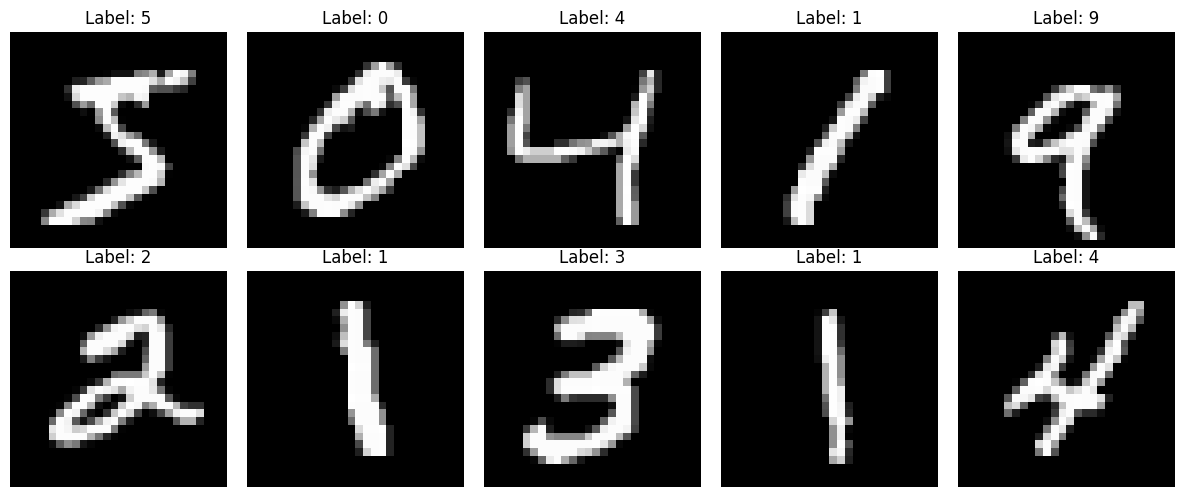

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    img, label = train_dataset[i]

    ax.imshow(img.squeeze().numpy(), cmap='gray')
    ax.set_title(f"Label: {label}")
    ax.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
training_size=54000
validation_size=6000
gen_var=torch.Generator().manual_seed(42)
train_set,train_val_set=random_split(train_dataset,[training_size,validation_size],generator=gen_var)

train_loader=DataLoader(train_set,batch_size=64,shuffle=True)
val_loader=DataLoader(train_val_set,batch_size=64,shuffle=False)
test_loader=DataLoader(test_dataset,batch_size=64,shuffle=False)

images, labels = next(iter(train_loader))
print(images.shape)
print(labels.shape)

torch.Size([64, 1, 28, 28])
torch.Size([64])


In [ ]:
class MLP(nn.Module):
  def __init__(self):
    super().__init__()
    self.model=nn.Sequential(
        nn.Linear(784,16),
        nn.ReLU(),
        nn.Linear(16,10)
    )
  def forward(self,x):
    x=x.reshape(x.shape[0],784)
    output=self.model(x)
    return output

In [ ]:
model = MLP()
model = model.to(device)
criterion = nn.CrossEntropyLoss()

In [ ]:
model=MLP()
model=model.to(device)
criterion=nn.CrossEntropyLoss()
learning_rate=0.001
optimizer=torch.optim.Adam(model.parameters(),lr=learning_rate)
print(model)
print(criterion)
print(optimizer)

MLP(
  (model): Sequential(
    (0): Linear(in_features=784, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=10, bias=True)
  )
)
CrossEntropyLoss()
Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [ ]:
epochs=30

In [ ]:

import os
import json
import time
import torch
import pandas as pd



# History of metrics
history = {
    "epoch": [],
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": [],
    "epoch_time_seconds": []
}

best_val_accuracy = 0.0

# Output directories
checkpoint_dir = os.path.join(proj_dir, "checkpoints")
logs_dir = os.path.join(proj_dir, "logs")
results_dir = os.path.join(proj_dir, "results")

os.makedirs(checkpoint_dir, exist_ok=True)
os.makedirs(logs_dir, exist_ok=True)
os.makedirs(results_dir, exist_ok=True)


# ---------------- TRAINING ----------------

for epoch in range(epochs):

    start_time = time.time()

    model.train()

    total_train_loss = 0.0
    total_train_samples = 0

    for batch_features, batch_labels in train_loader:

        batch_features = batch_features.to(device)
        batch_labels = batch_labels.to(device)

        optimizer.zero_grad()

        outputs = model(batch_features)

        loss = criterion(outputs, batch_labels)

        loss.backward()

        optimizer.step()

        batch_size = batch_labels.size(0)

        total_train_loss += loss.item() * batch_size
        total_train_samples += batch_size

    avg_train_loss = total_train_loss / total_train_samples


    # ---------------- VALIDATION ----------------

    model.eval()

    total_val_loss = 0.0
    total_val_samples = 0
    correct = 0

    with torch.no_grad():

        for batch_features, batch_labels in val_loader:

            batch_features = batch_features.to(device)
            batch_labels = batch_labels.to(device)

            outputs = model(batch_features)

            loss = criterion(outputs, batch_labels)

            batch_size = batch_labels.size(0)

            total_val_loss += loss.item() * batch_size
            total_val_samples += batch_size

            predicted = torch.argmax(outputs, dim=1)

            correct += (predicted == batch_labels).sum().item()

    avg_val_loss = total_val_loss / total_val_samples

    val_accuracy = 100.0 * correct / total_val_samples

    epoch_time = time.time() - start_time


    # ---------------- SAVE METRICS ----------------

    history["epoch"].append(epoch + 1)
    history["train_loss"].append(avg_train_loss)
    history["val_loss"].append(avg_val_loss)
    history["val_accuracy"].append(val_accuracy)
    history["epoch_time_seconds"].append(epoch_time)

    print(
        f"Epoch [{epoch+1}/{epochs}] | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.2f}% | "
        f"Time: {epoch_time:.2f}s"
    )


    # Save best model
    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy

        torch.save(
            model.state_dict(),
            os.path.join(checkpoint_dir, "best_model.pth")
        )


# ---------------- SAVE FINAL MODEL ----------------

torch.save(
    model.state_dict(),
    os.path.join(checkpoint_dir, "final_model.pth")
)


# Save training history
history_df = pd.DataFrame(history)

history_df.to_csv(
    os.path.join(logs_dir, "training_history.csv"),
    index=False
)


# Save experiment configuration
config = {
    "architecture": "784-16-10",
    "activation": "ReLU",
    "optimizer": "Adam",
    "learning_rate": learning_rate,
    "batch_size": 64,
    "epochs": epochs,
    "train_samples": len(train_loader.dataset),
    "validation_samples": len(val_loader.dataset),
    "test_samples": len(test_loader.dataset),
    "seed": 42
}

with open(os.path.join(results_dir, "experiment_config.json"), "w") as f:
    json.dump(config, f, indent=4)


print("\nTraining completed!")
print(f"Best validation accuracy: {best_val_accuracy:.2f}%")
print("Model checkpoints and training logs saved successfully.")


Epoch [1/30] | Train Loss: 0.5735 | Val Loss: 0.3140 | Val Accuracy: 90.88% | Time: 7.80s
Epoch [2/30] | Train Loss: 0.2820 | Val Loss: 0.2676 | Val Accuracy: 92.17% | Time: 7.30s
Epoch [3/30] | Train Loss: 0.2478 | Val Loss: 0.2487 | Val Accuracy: 92.63% | Time: 7.34s
Epoch [4/30] | Train Loss: 0.2228 | Val Loss: 0.2276 | Val Accuracy: 93.40% | Time: 7.34s
Epoch [5/30] | Train Loss: 0.2024 | Val Loss: 0.2203 | Val Accuracy: 93.55% | Time: 7.34s
Epoch [6/30] | Train Loss: 0.1891 | Val Loss: 0.2120 | Val Accuracy: 93.68% | Time: 7.29s
Epoch [7/30] | Train Loss: 0.1781 | Val Loss: 0.2056 | Val Accuracy: 94.15% | Time: 7.38s
Epoch [8/30] | Train Loss: 0.1698 | Val Loss: 0.2019 | Val Accuracy: 94.25% | Time: 7.33s
Epoch [9/30] | Train Loss: 0.1626 | Val Loss: 0.2022 | Val Accuracy: 94.17% | Time: 7.34s
Epoch [10/30] | Train Loss: 0.1564 | Val Loss: 0.1945 | Val Accuracy: 94.32% | Time: 7.37s
Epoch [11/30] | Train Loss: 0.1511 | Val Loss: 0.1931 | Val Accuracy: 94.38% | Time: 7.56s
Epoch [1

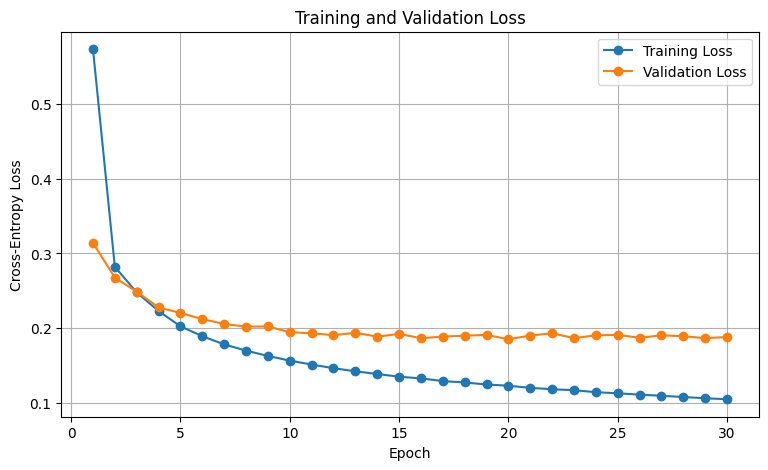

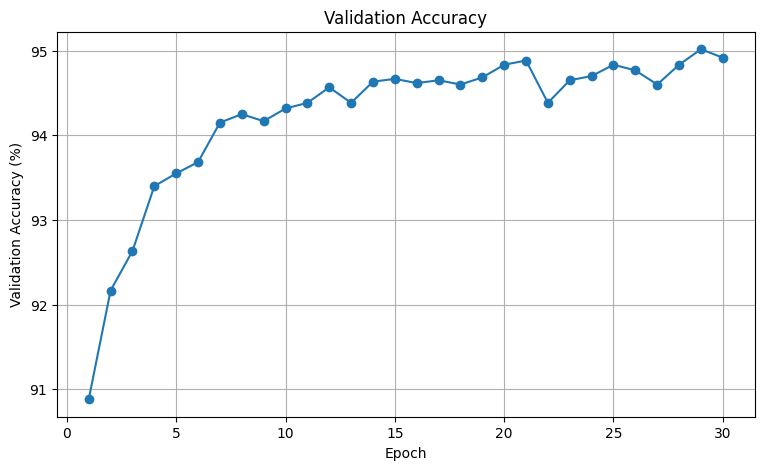

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(history["epoch"], history["train_loss"], marker="o", label="Training Loss")
plt.plot(history["epoch"], history["val_loss"], marker="o", label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.savefig(os.path.join(logs_dir, "loss_curve.png"))
plt.show()


plt.figure(figsize=(9, 5))

plt.plot(history["epoch"], history["val_accuracy"], marker="o")

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy (%)")
plt.title("Validation Accuracy")
plt.grid(True)
plt.savefig(os.path.join(logs_dir, "accuracy_curve.png"))
plt.show()


In [ ]:
checkpoint_dir="/content/drive/MyDrive/MLP_PROJECT_ONE/checkpoints"

In [ ]:
results_dir="/content/drive/MyDrive/MLP_PROJECT_ONE/results"

In [ ]:

best_model_path = os.path.join(
    checkpoint_dir,
    "best_model.pth"
)

state_dict = torch.load(
    best_model_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(state_dict)

model.eval()

print("Best trained model loaded successfully!")


Best trained model loaded successfully!


In [ ]:
import pandas as pd

In [ ]:

criterion = nn.CrossEntropyLoss()

total_loss = 0.0
total_correct = 0
total_samples = 0

# Per-class statistics
class_correct = [0] * 10
class_total = [0] * 10

# Store predictions
all_predictions = []
all_labels = []

# Confusion matrix
confusion_matrix = torch.zeros(10, 10, dtype=torch.int64)

start_time = time.time()

model.eval()

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        loss = criterion(outputs, labels)

        predicted = torch.argmax(outputs, dim=1)

        batch_size = labels.size(0)

        total_loss += loss.item() * batch_size
        total_samples += batch_size

        total_correct += (predicted == labels).sum().item()

        # Move predictions and labels to CPU
        predictions_cpu = predicted.cpu()
        labels_cpu = labels.cpu()

        all_predictions.extend(predictions_cpu.tolist())
        all_labels.extend(labels_cpu.tolist())

        # Per-class accuracy and confusion matrix
        for actual, prediction in zip(labels_cpu, predictions_cpu):

            class_total[actual.item()] += 1

            if actual == prediction:
                class_correct[actual.item()] += 1

            confusion_matrix[actual.item(), prediction.item()] += 1


evaluation_time = time.time() - start_time

test_loss = total_loss / total_samples
test_accuracy = 100.0 * total_correct / total_samples

print("========== TEST RESULTS ==========")
print(f"Test samples: {total_samples}")
print(f"Correct predictions: {total_correct}")
print(f"Incorrect predictions: {total_samples - total_correct}")
print(f"Test loss: {test_loss:.6f}")
print(f"Test accuracy: {test_accuracy:.4f}%")
print(f"Evaluation time: {evaluation_time:.2f} seconds")

print("\n========== PER-CLASS ACCURACY ==========")

for digit in range(10):

    accuracy = 100.0 * class_correct[digit] / class_total[digit]

    print(
        f"Digit {digit}: "
        f"{class_correct[digit]}/{class_total[digit]} "
        f"({accuracy:.2f}%)"
    )

# 1. Save overall and per-class metrics

test_metrics = {
    "architecture": "784-16-10",
    "activation": "ReLU",
    "checkpoint": "best_model.pth",
    "test_samples": total_samples,
    "correct_predictions": total_correct,
    "incorrect_predictions": total_samples - total_correct,
    "test_loss": test_loss,
    "test_accuracy_percent": test_accuracy,
    "evaluation_time_seconds": evaluation_time,
    "per_class_accuracy": {
        str(digit): (
            100.0 * class_correct[digit] / class_total[digit]
        )
        for digit in range(10)
    }
}

with open(os.path.join(results_dir, "test_metrics.json"), "w") as f:
    json.dump(test_metrics, f, indent=4)


# 2. Save confusion matrix

confusion_df = pd.DataFrame(
    confusion_matrix.numpy(),
    index=[f"Actual_{i}" for i in range(10)],
    columns=[f"Predicted_{i}" for i in range(10)]
)

confusion_df.to_csv(
    os.path.join(results_dir, "confusion_matrix.csv")
)


# 3. Save individual predictions

predictions_df = pd.DataFrame({
    "actual_label": all_labels,
    "predicted_label": all_predictions,
    "correct": [
        actual == predicted
        for actual, predicted in zip(all_labels, all_predictions)
    ]
})

predictions_df.to_csv(
    os.path.join(results_dir, "test_predictions.csv"),
    index=False
)

print("All test evaluation results saved successfully!")



========== TEST RESULTS ==========
Test samples: 10000
Correct predictions: 9539
Incorrect predictions: 461
Test loss: 0.167865
Test accuracy: 95.3900%
Evaluation time: 1.40 seconds

========== PER-CLASS ACCURACY ==========
Digit 0: 959/980 (97.86%)
Digit 1: 1114/1135 (98.15%)
Digit 2: 984/1032 (95.35%)
Digit 3: 952/1010 (94.26%)
Digit 4: 944/982 (96.13%)
Digit 5: 839/892 (94.06%)
Digit 6: 928/958 (96.87%)
Digit 7: 977/1028 (95.04%)
Digit 8: 908/974 (93.22%)
Digit 9: 934/1009 (92.57%)
All test evaluation results saved successfully!


In [ ]:
import os
import numpy as np
import json

exports_dir = os.path.join(proj_dir, "exports")
os.makedirs(exports_dir, exist_ok=True)

params = {
    "W1": model.model[0].weight.detach().cpu().numpy(),
    "b1": model.model[0].bias.detach().cpu().numpy(),
    "W2": model.model[2].weight.detach().cpu().numpy(),
    "b2": model.model[2].bias.detach().cpu().numpy()
}

# Save all four parameter arrays
np.savez(
    os.path.join(exports_dir, "mlp_parameters_float.npz"),
    **params
)

# Print parameter information
parameter_info = {}

for name, array in params.items():
    parameter_info[name] = {
        "shape": list(array.shape),
        "min": float(array.min()),
        "max": float(array.max()),
        "mean": float(array.mean()),
        "std": float(array.std())
    }

    print(f"\n{name}")
    print("Shape:", array.shape)
    print("Minimum:", array.min())
    print("Maximum:", array.max())
    print("Mean:", array.mean())
    print("Standard deviation:", array.std())

# Save the parameter information
with open(os.path.join(exports_dir, "parameter_info.json"), "w") as f:
    json.dump(parameter_info, f, indent=4)

print("\nParameter extraction completed.")


W1
Shape: (16, 784)
Minimum: -1.8162904
Maximum: 1.7790791
Mean: 0.0064674057
Standard deviation: 0.35718966

b1
Shape: (16,)
Minimum: -0.5952896
Maximum: 0.5923634
Mean: 0.08462085
Standard deviation: 0.33776692

W2
Shape: (10, 16)
Minimum: -1.7859803
Maximum: 1.0131832
Mean: -0.10735913
Standard deviation: 0.5836433

b2
Shape: (10,)
Minimum: -0.66740453
Maximum: 0.37409642
Mean: -0.08902564
Standard deviation: 0.36030608

Parameter extraction completed.


In [ ]:
# Inspect the parameter arrays
for name, array in params.items():
    print(name, array.shape, array.dtype)

# Inspect one MNIST image
images, labels = next(iter(test_loader))

sample = images[0]

print("Image shape:", sample.shape)
print("Minimum pixel value:", sample.min().item())
print("Maximum pixel value:", sample.max().item())
print("Label:", labels[0].item())

W1 (16, 784) float32
b1 (16,) float32
W2 (10, 16) float32
b2 (10,) float32
Image shape: torch.Size([1, 28, 28])
Minimum pixel value: 0.0
Maximum pixel value: 1.0
Label: 7


In [ ]:
model.eval()

MLP(
  (model): Sequential(
    (0): Linear(in_features=784, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=10, bias=True)
  )
)

In [ ]:
with torch.no_grad():
  images,labels=next(iter(test_loader))
  images=images.reshape(64,784)
  outputs=model.model[0](images)
  outputs=torch.relu(outputs)
  print("maximum activation value:",outputs.max())
  print("minimum activation value:",outputs.min())
  print("mean of values:",torch.mean(outputs))

maximum activation value: tensor(29.4329)
minimum activation value: tensor(0.)
mean of values: tensor(3.3438)


In [ ]:
with torch.no_grad():
  test_max=0
  test_min=float('inf')
  test_sum=0
  mean=0
  activation_value_count=0
  for images,labels in test_loader:
    batch_size=images.shape[0]
    images=images.reshape(batch_size,784)
    outputs_of_first=model.model[0](images)
    outputs_of_first=torch.relu(outputs_of_first)
    test_max=max(torch.max(outputs_of_first),test_max)
    test_min=min(torch.min(outputs_of_first),test_min)
    test_sum=test_sum+torch.sum(outputs_of_first)
    activation_value_count=activation_value_count+((outputs_of_first.shape[1])*batch_size)
  mean=test_sum/(activation_value_count)
  print(test_max)
  print(test_min)
  print(test_sum)
  print(mean)
  print(activation_value_count)


tensor(33.7206)
tensor(0.)
tensor(596338.1875)
tensor(3.7271)
160000


In [ ]:
print("Checkpoint being loaded:", best_model_path)
print("File exists:", os.path.exists(best_model_path))

Checkpoint being loaded: /content/drive/MyDrive/MLP_PROJECT_ONE/checkpoints/best_model.pth
File exists: True


In [ ]:
print(model.model[0].weight[0][:5])
print(model.model[0].bias[:5])

tensor([-0.0214, -0.0355,  0.0315,  0.0065, -0.0309], grad_fn=<SliceBackward0>)
tensor([ 0.3415,  0.5810,  0.2409, -0.0225,  0.4063], grad_fn=<SliceBackward0>)


In [ ]:
images, labels = next(iter(test_loader))

print("First five test labels:", labels[:5])
print("First five image shapes:", images[:5].shape)
print("First image pixel range:", images[0].min(), images[0].max())

First five test labels: tensor([7, 2, 1, 0, 4])
First five image shapes: torch.Size([5, 1, 28, 28])
First image pixel range: tensor(0.) tensor(1.)


In [ ]:
with torch.no_grad():
    images, labels = next(iter(test_loader))
    batch_size = images.shape[0]

    images = images.reshape(batch_size, 784)

    outputs = model.model[0](images)
    outputs = torch.relu(outputs)

    print("First batch maximum activation:", outputs.max())
    print("First batch minimum activation:", outputs.min())

First batch maximum activation: tensor(29.4329)
First batch minimum activation: tensor(0.)


In [ ]:
exports_dir = os.path.join(proj_dir, "exports")
loaded_data=np.load(os.path.join(exports_dir,"mlp_parameters_float.npz"))
weights_1=loaded_data['W1']
weights_2=loaded_data['W2']
weights_1_absolute_max=abs(weights_1).max()
weights_2_absolute_max=abs(weights_2).max()
weights_1_scale=127/(weights_1_absolute_max)
weights_2_scale=127/(weights_2_absolute_max)
weights_1_quantised=np.round(weights_1*(weights_1_scale))
weights_2_quantised=np.round(weights_2*(weights_2_scale))
weights_1_quantised=weights_1_quantised.astype(np.int8)
weights_2_quantised=weights_2_quantised.astype(np.int8)
print(weights_1_quantised.min())
print(weights_1_quantised.max())
print(weights_2_quantised.max())
print(weights_2_quantised.min())
has_large_number_one=(weights_1_quantised>127).any()
has_large_number_two=(weights_2_quantised>127).any()
has_small_number_one=(weights_1_quantised<-127).any()
has_small_number_two=(weights_2_quantised<-127).any()
if(has_large_number_one):
  print("weights_one has upper violation")
else:
  print("weights_one has no upper violation")

if(has_large_number_two):
  print("weights_two has  upper violation")
else:
  print("weights_two has no upper violation")

if(has_small_number_one):
  print("weights_one has  lower violation")
else:
  print("weights_one has no lower violation")

if(has_small_number_two):
  print("weights_two has lower violation")
else:
  print("weights_two has no lower violation")

-127
124
72
-127
weights_one has no upper violation
weights_two has no upper violation
weights_one has no lower violation
weights_two has no lower violation


In [ ]:
all_activations = []

with torch.no_grad():
    for images, labels in test_loader:
        batch_size = images.shape[0]

        images = images.reshape(batch_size, 784)

        outputs = model.model[0](images)
        outputs = torch.relu(outputs)

        all_activations.append(outputs.cpu().numpy())

outputs_of_first_layer = np.concatenate(all_activations, axis=0)

print("Activation shape:", outputs_of_first_layer.shape)
print("Maximum:", outputs_of_first_layer.max())
print("Minimum:", outputs_of_first_layer.min())
print("Mean:", outputs_of_first_layer.mean())

Activation shape: (10000, 16)
Maximum: 33.720592
Minimum: 0.0
Mean: 3.7271125


In [ ]:
# 1. First five weights of the first hidden neuron
print("First five weights:")
print(model.model[0].weight[0][:5].detach().cpu().numpy())

# 2. First five biases of the first layer
print("\nFirst five biases:")
print(model.model[0].bias[:5].detach().cpu().numpy())

# 3. First five labels from the test dataset
print("\nFirst five test labels:")
images, labels = next(iter(test_loader))
print(labels[:5].cpu().numpy())

# 4. Collect activations again
all_activations = []

with torch.no_grad():
    for images, labels in test_loader:
        batch_size = images.shape[0]

        images = images.reshape(batch_size, 784)

        outputs = model.model[0](images)
        outputs = torch.relu(outputs)

        all_activations.append(outputs.cpu().numpy())

outputs_of_first_layer = np.concatenate(all_activations, axis=0)

print("\nActivation statistics:")
print("Shape:", outputs_of_first_layer.shape)
print("Maximum:", outputs_of_first_layer.max())
print("Minimum:", outputs_of_first_layer.min())
print("Mean:", outputs_of_first_layer.mean())

First five weights:
[-0.02136548 -0.03548549  0.03149288  0.00654623 -0.03089776]

First five biases:
[ 0.3414753   0.58098257  0.24092662 -0.02247355  0.4063115 ]

First five test labels:
[7 2 1 0 4]

Activation statistics:
Shape: (10000, 16)
Maximum: 33.720596
Minimum: 0.0
Mean: 3.7271125


In [ ]:
maximum_first_layer_activation=33.720596
first_layer_activation_scale=255/(maximum_first_layer_activation)
quantised_outputs_of_first_layer=outputs_of_first_layer*(first_layer_activation_scale)
quantised_outputs_of_first_layer=np.round(quantised_outputs_of_first_layer)
print(quantised_outputs_of_first_layer.max())
print(quantised_outputs_of_first_layer.min())
has_large_number_one_output=(quantised_outputs_of_first_layer>255).any()
has_small_number_one_output=(quantised_outputs_of_first_layer<0).any()
if(has_large_number_one_output):
  print("weights_one has upper violation")
else:
  print("weights_one has no upper violation")

if(has_small_number_one_output):
  print("weights_one has  lower violation")
else:
  print("weights_one has no lower violation")
if((has_large_number_one_output==0)and(has_small_number_one_output==0)):
  quantised_outputs_of_first_layer=quantised_outputs_of_first_layer.astype(np.uint8)

255.0
0.0
weights_one has no upper violation
weights_one has no lower violation


In [ ]:
print("Data type:", quantised_outputs_of_first_layer.dtype)
print("Shape:", quantised_outputs_of_first_layer.shape)
print("Maximum:", quantised_outputs_of_first_layer.max())
print("Minimum:", quantised_outputs_of_first_layer.min())

Data type: uint8
Shape: (10000, 16)
Maximum: 255
Minimum: 0


In [ ]:
N = outputs_of_first_layer.size

reconstructed_activations = quantised_outputs_of_first_layer.astype(np.float32)
reconstructed_activations = reconstructed_activations / first_layer_activation_scale

error_array = outputs_of_first_layer - reconstructed_activations

maximum_absolute_error = np.max(np.abs(error_array))

mean_absolute_error = np.mean(np.abs(error_array))

root_mean_square_error = np.sqrt(np.mean(error_array**2))

print("Maximum absolute error:", maximum_absolute_error)
print("Mean absolute error:", mean_absolute_error)
print("Root mean square error:", root_mean_square_error)

Maximum absolute error: 0.06611824
Mean absolute error: 0.02298232
Root mean square error: 0.031835742


In [ ]:
print("W1 dtype:", weights_1_quantised.dtype)
print("W2 dtype:", weights_2_quantised.dtype)

print("W1 shape:", weights_1_quantised.shape)
print("W2 shape:", weights_2_quantised.shape)

W1 dtype: int8
W2 dtype: int8
W1 shape: (16, 784)
W2 shape: (10, 16)


In [ ]:
images, labels = next(iter(test_loader))

print("Original minimum:", images.min().item())
print("Original maximum:", images.max().item())

integer_images = torch.round(images * 255).to(torch.uint8)

print("Integer minimum:", integer_images.min().item())
print("Integer maximum:", integer_images.max().item())
print("Integer data type:", integer_images.dtype)

Original minimum: 0.0
Original maximum: 1.0
Integer minimum: 0
Integer maximum: 255
Integer data type: torch.uint8


In [ ]:
exports_dir = os.path.join(proj_dir, "exports")
loaded_data=np.load(os.path.join(exports_dir,"mlp_parameters_float.npz"))
bias_1=loaded_data['b1']
bias_2=loaded_data['b2']
bias_1_scale=weights_1_scale*255
bias_2_scale=first_layer_activation_scale*weights_2_scale
quantised_bias_1=bias_1_scale*(bias_1)
quantised_bias_2=bias_2_scale*(bias_2)
quantised_bias_1=np.round(quantised_bias_1)
quantised_bias_2=np.round(quantised_bias_2)
print(quantised_bias_1.min())
print(quantised_bias_2.min())
print(quantised_bias_1.max())
print(quantised_bias_2.max())

-10614.0
-359.0
10562.0
201.0


In [ ]:
maximum_product = 255 * 127

maximum_first_layer_mac = 784 * maximum_product

maximum_first_layer_bias = max(
    abs(quantised_bias_1.min()),
    abs(quantised_bias_1.max())
)

maximum_first_layer_accumulator = (
    maximum_first_layer_mac + maximum_first_layer_bias
)

print("Maximum product:", maximum_product)
print("Maximum MAC sum:", maximum_first_layer_mac)
print("Maximum bias magnitude:", maximum_first_layer_bias)
print("Maximum accumulator magnitude:", maximum_first_layer_accumulator)

Maximum product: 32385
Maximum MAC sum: 25389840
Maximum bias magnitude: 10614.0
Maximum accumulator magnitude: 25400454.0


In [ ]:
maximum_second_layer_product = 255 * 127

maximum_second_layer_mac = 16 * maximum_second_layer_product

maximum_second_layer_bias = max(
    abs(quantised_bias_2.min()),
    abs(quantised_bias_2.max())
)

maximum_second_layer_accumulator = (
    maximum_second_layer_mac + maximum_second_layer_bias
)

print("Maximum product:", maximum_second_layer_product)
print("Maximum MAC sum:", maximum_second_layer_mac)
print("Maximum bias magnitude:", maximum_second_layer_bias)
print("Maximum accumulator magnitude:", maximum_second_layer_accumulator)

Maximum product: 32385
Maximum MAC sum: 518160
Maximum bias magnitude: 359.0
Maximum accumulator magnitude: 518519.0


In [ ]:
first_layer_rescaling_factor = (
    first_layer_activation_scale / (255 * weights_1_scale)
)

print("First-layer rescaling factor:", first_layer_rescaling_factor)

First-layer rescaling factor: 0.0004241176


In [ ]:
test_images=[]
for image,label in test_loader:
  batch_size=image.shape[0]
  image=image.reshape(batch_size,784)
  image=image*255
  image=np.round(image)
  image=image.to(torch.uint8)
  image=image.cpu().numpy()
  test_images.append(image)
test_images=np.concatenate(test_images,axis=0)
print(test_images.shape)
print(test_images.dtype)
print(test_images.min())
print(test_images.max())

(10000, 784)
uint8
0
255


In [ ]:
test_images=test_images.astype(np.int64)
weights_1_quantised=weights_1_quantised.astype(np.int64)
quantised_bias_1=quantised_bias_1.astype(np.int64)
A=(test_images@(weights_1_quantised.T))+quantised_bias_1
print(A.shape)
print(A.dtype)
print(A.min())
print(A.max())

(10000, 16)
int64
-729588
602567


In [ ]:
second_layer_input=np.maximum(A,0)
second_layer_input=second_layer_input*first_layer_rescaling_factor
second_layer_input=np.round(second_layer_input)
second_layer_input=np.clip(second_layer_input,0,255)
print(second_layer_input.shape)
print(second_layer_input.min())
print(second_layer_input.max())
print(second_layer_input.dtype)

(10000, 16)
0.0
255.0
float64


In [ ]:
second_layer_input=second_layer_input.astype(np.uint8)

In [ ]:
second_layer_input=second_layer_input.astype(np.int64)
weights_2_quantised=weights_2_quantised.astype(np.int64)
quantised_bias_2=quantised_bias_2.astype(np.int64)
A2=(second_layer_input@(weights_2_quantised.T))+quantised_bias_2
print(A2.shape)
print(A2.dtype)
print(A2.min())
print(A2.max())

(10000, 10)
int64
-30179
17223


In [ ]:
prediction = np.argmax(A2, axis=1)

print("Prediction shape:", prediction.shape)
print("First 10 predictions:", prediction[:10])

Prediction shape: (10000,)
First 10 predictions: [7 2 1 0 4 1 4 9 6 9]


In [ ]:
actual_labels = []

for images, labels in test_loader:
    actual_labels.append(labels.numpy())

actual_labels = np.concatenate(actual_labels, axis=0)

print("Actual labels shape:", actual_labels.shape)
print("First 10 actual labels:", actual_labels[:10])

Actual labels shape: (10000,)
First 10 actual labels: [7 2 1 0 4 1 4 9 5 9]


In [ ]:
correct_predictions = np.sum(prediction == actual_labels)

accuracy = (correct_predictions / len(actual_labels)) * 100

print("Correct predictions:", correct_predictions)
print("Total images:", len(actual_labels))
print("Integer model accuracy:", accuracy, "%")

Correct predictions: 9535
Total images: 10000
Integer model accuracy: 95.35 %


In [ ]:
model.eval()
correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        predicted = torch.argmax(outputs, dim=1)

        correct += (predicted == labels).sum().item()
        total += labels.size(0)

pytorch_accuracy = 100 * correct / total

print("PyTorch accuracy:", pytorch_accuracy, "%")

PyTorch accuracy: 95.39 %


In [ ]:
torch_predictions = []

model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predicted = torch.argmax(outputs, dim=1)

        torch_predictions.append(predicted.cpu().numpy())

torch_predictions = np.concatenate(torch_predictions, axis=0)

In [ ]:
different_predictions = np.sum(prediction != actual_labels)
print("Integer model errors:", np.sum(prediction != actual_labels))
print("PyTorch model errors:", np.sum(
    torch_predictions != actual_labels
))
print("Prediction disagreements:", different_predictions)

Integer model errors: 465
PyTorch model errors: 461
Prediction disagreements: 465


In [ ]:
disagreement_indices = np.where(prediction != torch_predictions)[0]

print("Number of disagreements:", len(disagreement_indices))
print("First 20 disagreement indices:", disagreement_indices[:20])

print("\nFirst 10 disagreements:")
for i in disagreement_indices[:10]:
    print(
        "Image:", i,
        "| Actual:", actual_labels[i],
        "| Integer:", prediction[i],
        "| PyTorch:", torch_predictions[i]
    )

Number of disagreements: 42
First 20 disagreement indices: [ 115  151  578  877 1581 1992 2099 2129 2369 2422 2670 2742 2979 3166
 3193 3629 3757 3817 3926 3951]

First 10 disagreements:
Image: 115 | Actual: 4 | Integer: 4 | PyTorch: 9
Image: 151 | Actual: 9 | Integer: 8 | PyTorch: 9
Image: 578 | Actual: 3 | Integer: 3 | PyTorch: 2
Image: 877 | Actual: 8 | Integer: 6 | PyTorch: 8
Image: 1581 | Actual: 7 | Integer: 7 | PyTorch: 3
Image: 1992 | Actual: 9 | Integer: 8 | PyTorch: 9
Image: 2099 | Actual: 8 | Integer: 4 | PyTorch: 8
Image: 2129 | Actual: 9 | Integer: 7 | PyTorch: 9
Image: 2369 | Actual: 5 | Integer: 4 | PyTorch: 9
Image: 2422 | Actual: 6 | Integer: 7 | PyTorch: 4


In [ ]:
integer_correct = prediction == actual_labels
pytorch_correct = torch_predictions == actual_labels

integer_better = np.sum(integer_correct & ~pytorch_correct)
pytorch_better = np.sum(~integer_correct & pytorch_correct)
both_wrong = np.sum(~integer_correct & ~pytorch_correct & (prediction != torch_predictions))

print("Integer correct, PyTorch wrong:", integer_better)
print("PyTorch correct, integer wrong:", pytorch_better)
print("Both wrong, different predictions:", both_wrong)

Integer correct, PyTorch wrong: 13
PyTorch correct, integer wrong: 17
Both wrong, different predictions: 12


In [ ]:
weights_1_quantised = weights_1_quantised.astype(np.int8)
weights_2_quantised = weights_2_quantised.astype(np.int8)

In [ ]:
print(weights_1_quantised.dtype)
print(weights_2_quantised.dtype)

int8
int8


In [ ]:
np.savez(
    os.path.join(exports_dir, "weights_quantized.npz"),
    W1=weights_1_quantised,
    W2=weights_2_quantised
)

In [ ]:
saved_weights = np.load(
    os.path.join(exports_dir, "weights_quantized.npz")
)

print(saved_weights.files)

print("W1:", saved_weights["W1"].shape,
      saved_weights["W1"].dtype,
      saved_weights["W1"].min(),
      saved_weights["W1"].max())

print("W2:", saved_weights["W2"].shape,
      saved_weights["W2"].dtype,
      saved_weights["W2"].min(),
      saved_weights["W2"].max())

['W1', 'W2']
W1: (16, 784) int8 -127 124
W2: (10, 16) int8 -127 72


In [ ]:
quantised_bias_1 = quantised_bias_1.astype(np.int32)
quantised_bias_2 = quantised_bias_2.astype(np.int32)

In [ ]:
np.savez(
    os.path.join(exports_dir, "biases_quantized.npz"),
    b1=quantised_bias_1,
    b2=quantised_bias_2
)

In [ ]:
saved_biases = np.load(
    os.path.join(exports_dir, "biases_quantized.npz")
)

print("b1:", saved_biases["b1"].shape,
      saved_biases["b1"].dtype,
      saved_biases["b1"].min(),
      saved_biases["b1"].max())

print("b2:", saved_biases["b2"].shape,
      saved_biases["b2"].dtype,
      saved_biases["b2"].min(),
      saved_biases["b2"].max())

b1: (16,) int32 -10614 10562
b2: (10,) int32 -359 201


In [ ]:
import json
import os

quantization_config = {
    "architecture": [784, 16, 10],

    "input_scale": 255,
    "input_bits": 8,

    "weight_1_scale": float(weights_1_scale),
    "weight_2_scale": float(weights_2_scale),

    "weight_bits": 8,

    "first_layer_activation_scale": float(first_layer_activation_scale),
    "first_layer_rescaling_factor": float(first_layer_rescaling_factor),

    "hidden_activation_bits": 8,

    "first_accumulator_bits": 26,
    "second_accumulator_bits": 20,

    "bias_1_bits": 32,
    "bias_2_bits": 32,

    "activation_function": "ReLU",
    "output_function": "argmax"
}

config_path = os.path.join(exports_dir, "quantization_config.json")

with open(config_path, "w") as file:
    json.dump(quantization_config, file, indent=4)

print("Configuration saved successfully!")

Configuration saved successfully!


In [ ]:
with open(config_path, "r") as file:
    loaded_config = json.load(file)

print(json.dumps(loaded_config, indent=4))

{
    "architecture": [
        784,
        16,
        10
    ],
    "input_scale": 255,
    "input_bits": 8,
    "weight_1_scale": 69.92273712158203,
    "weight_2_scale": 71.10940551757812,
    "weight_bits": 8,
    "first_layer_activation_scale": 7.562143919401661,
    "first_layer_rescaling_factor": 0.00042411760659888387,
    "hidden_activation_bits": 8,
    "first_accumulator_bits": 26,
    "second_accumulator_bits": 20,
    "bias_1_bits": 32,
    "bias_2_bits": 32,
    "activation_function": "ReLU",
    "output_function": "argmax"
}


In [ ]:
parameter_info = {
    "architecture": "784-16-10",

    "W1": {
        "shape": list(weights_1_quantised.shape),
        "dtype": str(weights_1_quantised.dtype),
        "min": int(weights_1_quantised.min()),
        "max": int(weights_1_quantised.max())
    },

    "b1": {
        "shape": list(quantised_bias_1.shape),
        "dtype": str(quantised_bias_1.dtype),
        "min": int(quantised_bias_1.min()),
        "max": int(quantised_bias_1.max())
    },

    "W2": {
        "shape": list(weights_2_quantised.shape),
        "dtype": str(weights_2_quantised.dtype),
        "min": int(weights_2_quantised.min()),
        "max": int(weights_2_quantised.max())
    },

    "b2": {
        "shape": list(quantised_bias_2.shape),
        "dtype": str(quantised_bias_2.dtype),
        "min": int(quantised_bias_2.min()),
        "max": int(quantised_bias_2.max())
    }
}

info_path = os.path.join(exports_dir, "parameter_info.json")

with open(info_path, "w") as file:
    json.dump(parameter_info, file, indent=4)

print(json.dumps(parameter_info, indent=4))

{
    "architecture": "784-16-10",
    "W1": {
        "shape": [
            16,
            784
        ],
        "dtype": "int8",
        "min": -127,
        "max": 124
    },
    "b1": {
        "shape": [
            16
        ],
        "dtype": "int32",
        "min": -10614,
        "max": 10562
    },
    "W2": {
        "shape": [
            10,
            16
        ],
        "dtype": "int8",
        "min": -127,
        "max": 72
    },
    "b2": {
        "shape": [
            10
        ],
        "dtype": "int32",
        "min": -359,
        "max": 201
    }
}


In [ ]:
import os
import numpy as np

def save_mem_file(array, filepath, bit_width):
    hex_digits = bit_width // 4
    mask = (1 << bit_width) - 1

    with open(filepath, "w") as file:
        for value in array.flatten(order="C"):
            value = int(value) & mask
            file.write(f"{value:0{hex_digits}X}\n")


# Weight files: row-major order
save_mem_file(
    weights_1_quantised,
    os.path.join(exports_dir, "W1.mem"),
    8
)

save_mem_file(
    weights_2_quantised,
    os.path.join(exports_dir, "W2.mem"),
    8
)

# Bias files: neuron-index order
save_mem_file(
    quantised_bias_1,
    os.path.join(exports_dir, "b1.mem"),
    32
)

save_mem_file(
    quantised_bias_2,
    os.path.join(exports_dir, "b2.mem"),
    32
)

print("All four memory files generated successfully!")

All four memory files generated successfully!


In [ ]:
mem_files = {
    "W1.mem": (16 * 784, 2),
    "W2.mem": (10 * 16, 2),
    "b1.mem": (16, 8),
    "b2.mem": (10, 8)
}

for filename, (expected_lines, expected_digits) in mem_files.items():
    filepath = os.path.join(exports_dir, filename)

    with open(filepath, "r") as file:
        lines = file.read().splitlines()

    print(f"\n{filename}")
    print("Number of values:", len(lines))
    print("Expected values:", expected_lines)
    print("First 5 values:", lines[:5])
    print("Hex digits per value:", len(lines[0]) if lines else 0)

    assert len(lines) == expected_lines
    assert all(len(value) == expected_digits for value in lines)

print("\nAll memory file structural checks passed!")


W1.mem
Number of values: 12544
Expected values: 12544
First 5 values: ['FF', 'FE', '02', '00', 'FE']
Hex digits per value: 2

W2.mem
Number of values: 160
Expected values: 160
First 5 values: ['08', '06', 'E0', 'BE', 'BD']
Hex digits per value: 2

b1.mem
Number of values: 16
Expected values: 16
First 5 values: ['000017C9', '00002877', '000010C8', 'FFFFFE6F', '00001C4D']
Hex digits per value: 8

b2.mem
Number of values: 10
Expected values: 10
First 5 values: ['FFFFFECA', '00000056', '0000004E', 'FFFFFE99', '000000C9']
Hex digits per value: 8

All memory file structural checks passed!


In [ ]:
from pathlib import Path

PROJECT_ROOT = Path("/content/drive/MyDrive/MLP_PROJECT_ONE")

DATA_DIR = PROJECT_ROOT / "data"
EXPORT_DIR = PROJECT_ROOT / "exports"
TEST_VECTOR_DIR = EXPORT_DIR / "test_vectors"
IMAGE_DIR = PROJECT_ROOT / "results" / "test_images"

TEST_VECTOR_DIR.mkdir(parents=True, exist_ok=True)
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_ROOT)
print("Test vectors directory:", TEST_VECTOR_DIR)
print("Image directory:", IMAGE_DIR)

Project directory: /content/drive/MyDrive/MLP_PROJECT_ONE
Test vectors directory: /content/drive/MyDrive/MLP_PROJECT_ONE/exports/test_vectors
Image directory: /content/drive/MyDrive/MLP_PROJECT_ONE/results/test_images


In [ ]:
from torchvision import datasets

test_dataset = datasets.MNIST(
    root=str(DATA_DIR),
    train=False,
    download=True
)

print("Number of test images:", len(test_dataset))

Number of test images: 10000


In [ ]:
import numpy as np
from PIL import Image

image_index = 0

image, label = test_dataset[image_index]

# Convert the PIL image directly to an unsigned 8-bit array
pixels = np.asarray(image, dtype=np.uint8)

# Flatten the 28 x 28 image into 784 pixels
flat_pixels = pixels.reshape(-1)

print("Image shape:", pixels.shape)
print("Flattened shape:", flat_pixels.shape)
print("Label:", label)
print("Minimum pixel:", flat_pixels.min())
print("Maximum pixel:", flat_pixels.max())

Image shape: (28, 28)
Flattened shape: (784,)
Label: 7
Minimum pixel: 0
Maximum pixel: 255


In [ ]:
# Save the original image for reference
image_path = IMAGE_DIR / f"image_{image_index:05d}_label_{label}.png"
image.save(image_path)

# Save all 784 pixels as two-digit hexadecimal values
mem_path = TEST_VECTOR_DIR / "input.mem"

with open(mem_path, "w") as f:
    for pixel in flat_pixels:
        f.write(f"{int(pixel):02X}\n")

print("Image saved:", image_path)
print("Memory file saved:", mem_path)
print("Number of memory entries:", len(flat_pixels))

Image saved: /content/drive/MyDrive/MLP_PROJECT_ONE/results/test_images/image_00000_label_7.png
Memory file saved: /content/drive/MyDrive/MLP_PROJECT_ONE/exports/test_vectors/input.mem
Number of memory entries: 784


In [ ]:
loaded_pixels = np.loadtxt(
    mem_path,
    dtype=np.uint8,
    delimiter=None,
    converters={0: lambda x: int(x, 16)}
)

assert len(loaded_pixels) == 784
assert np.array_equal(flat_pixels, loaded_pixels)

print("Memory export verification PASSED")

Memory export verification PASSED


In [ ]:
from google.colab import files

files.download(str(mem_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
from pathlib import Path
import numpy as np
import json

PROJECT_ROOT = Path("/content/drive/MyDrive/MLP_PROJECT_ONE")
EXPORT_DIR = PROJECT_ROOT / "exports"
TEST_VECTOR_DIR = EXPORT_DIR / "test_vectors"

# Inspect quantized weight file
weights = np.load(EXPORT_DIR / "weights_quantized.npz")

print("WEIGHT FILE KEYS:")
for key in weights.files:
    print(key, weights[key].shape, weights[key].dtype)

# Inspect quantized bias file
biases = np.load(EXPORT_DIR / "biases_quantized.npz")

print("\nBIAS FILE KEYS:")
for key in biases.files:
    print(key, biases[key].shape, biases[key].dtype)

# Inspect quantization configuration
with open(EXPORT_DIR / "quantization_config.json", "r") as f:
    config = json.load(f)

print("\nQUANTIZATION CONFIGURATION:")
print(json.dumps(config, indent=2))

# Check the input image
input_path = TEST_VECTOR_DIR / "input.mem"

pixels = np.array(
    [int(line.strip(), 16) for line in input_path.read_text().splitlines()],
    dtype=np.uint8
)

print("\nINPUT IMAGE:")
print("Number of pixels:", len(pixels))
print("First 10 pixels:", pixels[:10])

WEIGHT FILE KEYS:
W1 (16, 784) int8
W2 (10, 16) int8

BIAS FILE KEYS:
b1 (16,) int32
b2 (10,) int32

QUANTIZATION CONFIGURATION:
{
  "architecture": [
    784,
    16,
    10
  ],
  "input_scale": 255,
  "input_bits": 8,
  "weight_1_scale": 69.92273712158203,
  "weight_2_scale": 71.10940551757812,
  "weight_bits": 8,
  "first_layer_activation_scale": 7.562143919401661,
  "first_layer_rescaling_factor": 0.00042411760659888387,
  "hidden_activation_bits": 8,
  "first_accumulator_bits": 26,
  "second_accumulator_bits": 20,
  "bias_1_bits": 32,
  "bias_2_bits": 32,
  "activation_function": "ReLU",
  "output_function": "argmax"
}

INPUT IMAGE:
Number of pixels: 784
First 10 pixels: [0 0 0 0 0 0 0 0 0 0]


In [3]:

from pathlib import Path
import numpy as np

# Project paths
PROJECT_ROOT = Path("/content/drive/MyDrive/MLP_PROJECT_ONE")
EXPORT_DIR = PROJECT_ROOT / "exports"
TEST_VECTOR_DIR = EXPORT_DIR / "test_vectors"

# Create directory if it does not exist
TEST_VECTOR_DIR.mkdir(parents=True, exist_ok=True)

# Load quantized parameters
weights = np.load(EXPORT_DIR / "weights_quantized.npz")
biases = np.load(EXPORT_DIR / "biases_quantized.npz")

W1 = weights["W1"].astype(np.int64)
b1 = biases["b1"].astype(np.int64)

# Load the exact input image used by the RTL
input_path = TEST_VECTOR_DIR / "input.mem"

pixels = np.array(
    [int(line.strip(), 16)
     for line in input_path.read_text().splitlines()],
    dtype=np.int64
)

# Validate dimensions
assert W1.shape == (16, 784)
assert b1.shape == (16,)
assert pixels.shape == (784,)
assert np.all((pixels >= 0) & (pixels <= 255))

# Calculate first-layer accumulators
# acc[j] = bias[j] + sum(pixels[i] * W1[j][i])

accumulators = b1 + W1 @ pixels

# Verify signed 26-bit accumulator range
assert np.all(accumulators >= -(2**25))
assert np.all(accumulators <= (2**25 - 1))

# Apply the exact arithmetic used in your RTL
relu_values = np.maximum(accumulators, 0)

scaled_values = (
    (relu_values * 7116 + (2**23)) >> 24
)

# Saturate to unsigned 8-bit range
hidden_activations = np.clip(
    scaled_values, 0, 255
).astype(np.uint8)

# Export expected activations as hexadecimal
output_path = TEST_VECTOR_DIR / "expected_hidden.mem"

with open(output_path, "w") as f:
    for value in hidden_activations:
        f.write(f"{int(value):02X}\n")

# Display results
print("FIRST-LAYER EXPECTED ACTIVATIONS")
print("--------------------------------")

for neuron, value in enumerate(hidden_activations):
    print(
        f"Neuron {neuron:2d}: "
        f"Decimal = {int(value):3d}, "
        f"Hex = {int(value):02X}"
    )

print("--------------------------------")
print("Number of activations:", len(hidden_activations))
print("Output file:", output_path)
print("File size:", len(output_path.read_text().splitlines()))

assert len(hidden_activations) == 16
print("\nEXPECTED ACTIVATION EXPORT SUCCESSFUL")


FIRST-LAYER EXPECTED ACTIVATIONS
--------------------------------
Neuron  0: Decimal =  22, Hex = 16
Neuron  1: Decimal =  18, Hex = 12
Neuron  2: Decimal =   0, Hex = 00
Neuron  3: Decimal =  51, Hex = 33
Neuron  4: Decimal =   0, Hex = 00
Neuron  5: Decimal =   3, Hex = 03
Neuron  6: Decimal =   0, Hex = 00
Neuron  7: Decimal =  80, Hex = 50
Neuron  8: Decimal =   0, Hex = 00
Neuron  9: Decimal =  55, Hex = 37
Neuron 10: Decimal =  39, Hex = 27
Neuron 11: Decimal =  50, Hex = 32
Neuron 12: Decimal =  11, Hex = 0B
Neuron 13: Decimal =   0, Hex = 00
Neuron 14: Decimal =  64, Hex = 40
Neuron 15: Decimal =  33, Hex = 21
--------------------------------
Number of activations: 16
Output file: /content/drive/MyDrive/MLP_PROJECT_ONE/exports/test_vectors/expected_hidden.mem
File size: 16

EXPECTED ACTIVATION EXPORT SUCCESSFUL


In [5]:
from google.colab import files

files.download(
    "/content/drive/MyDrive/MLP_PROJECT_ONE/exports/test_vectors/expected_hidden.mem"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
import numpy as np

PROJECT_DIR = "/content/drive/MyDrive/MLP_PROJECT_ONE"
EXPORT_DIR = os.path.join(PROJECT_DIR, "exports")

print("Exports folder exists:", os.path.exists(EXPORT_DIR))
print("Files:", os.listdir(EXPORT_DIR))

Mounted at /content/drive
Exports folder exists: True
Files: ['mlp_parameters_float.npz', 'weights_quantized.npz', 'biases_quantized.npz', 'quantization_config.json', 'parameter_info.json', 'W1.mem', 'W2.mem', 'b1.mem', 'b2.mem', 'test_vectors']


In [5]:
import os
import numpy as np

PROJECT_DIR = "/content/drive/MyDrive/MLP_PROJECT_ONE"
EXPORT_DIR = os.path.join(PROJECT_DIR, "exports")

def read_signed_hex(filename, bits):
    with open(filename, "r") as f:
        values = [
            int(line.strip(), 16)
            for line in f
            if line.strip()
        ]

    sign_bit = 1 << (bits - 1)
    modulus = 1 << bits

    return np.array([
        value - modulus if value & sign_bit else value
        for value in values
    ], dtype=np.int64)


# Read second-layer weights and biases
W2 = read_signed_hex(
    os.path.join(EXPORT_DIR, "W2.mem"), 8
).reshape(10, 16)

b2 = read_signed_hex(
    os.path.join(EXPORT_DIR, "b2.mem"), 32
)

print("W2 shape:", W2.shape)
print("b2 shape:", b2.shape)

print("W2 sample:")
print(W2[:2])

print("b2:")
print(b2)

W2 shape: (10, 16)
b2 shape: (10,)
W2 sample:
[[   8    6  -32  -66  -67  -14 -113   13   41  -70   34    8   36   17
   -21   28]
 [  72   15    5    3    3   17   -3  -81   -1  -64  -66  -13   43   40
    10  -16]]
b2:
[-310   86   78 -359  201  136  -21   84 -295  -78]


In [6]:
TEST_VECTOR_DIR = os.path.join(EXPORT_DIR, "test_vectors")

print(os.listdir(TEST_VECTOR_DIR))


['input.mem', 'expected_hidden.mem']


In [7]:
hidden_file = os.path.join(
    TEST_VECTOR_DIR, "expected_hidden.mem"
)

with open(hidden_file, "r") as f:
    hidden = np.array(
        [int(line.strip(), 16) for line in f if line.strip()],
        dtype=np.int64
    )

print("Hidden shape:", hidden.shape)
print("Hidden activations:", hidden)

assert hidden.shape == (16,)

Hidden shape: (16,)
Hidden activations: [22 18  0 51  0  3  0 80  0 55 39 50 11  0 64 33]


In [8]:
logits = b2 + W2 @ hidden

print("\nSECOND LAYER INTEGER LOGITS")
print("---------------------------")

for i, value in enumerate(logits):
    print(f"Neuron {i}: {value}")

assert np.all(logits >= -(2**25))
assert np.all(logits <= (2**25) - 1)

print("\nAll logits fit in signed 26-bit range.")


SECOND LAYER INTEGER LOGITS
---------------------------
Neuron 0: -4542
Neuron 1: -10495
Neuron 2: -1284
Neuron 3: 1895
Neuron 4: -6812
Neuron 5: -1094
Neuron 6: -14950
Neuron 7: 5987
Neuron 8: -518
Neuron 9: -1504

All logits fit in signed 26-bit range.


In [9]:
output_file = os.path.join(
    EXPORT_DIR, "expected_logits.mem"
)

with open(output_file, "w") as f:
    for value in logits:
        hex_value = int(value) & 0x3FFFFFF
        f.write(f"{hex_value:07X}\n")

print("Saved:", output_file)

Saved: /content/drive/MyDrive/MLP_PROJECT_ONE/exports/expected_logits.mem


In [10]:
with open(output_file, "r") as f:
    print(f.read())

3FFEE42
3FFD701
3FFFAFC
0000767
3FFE564
3FFFBBA
3FFC59A
0001763
3FFFDFA
3FFFA20



In [3]:
import os

proj_dir = "/content/drive/MyDrive/MLP_PROJECT_ONE"

for root, dirs, files in os.walk(proj_dir):
    level = root.replace(proj_dir, "").count(os.sep)
    indent = " " * 4 * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        print(f"{indent}    {file}")

MLP_PROJECT_ONE/
    notebooks/
        MLP_MNIST_Training.ipynb
    checkpoints/
        best_model.pth
        final_model.pth
    exports/
        mlp_parameters_float.npz
        weights_quantized.npz
        biases_quantized.npz
        quantization_config.json
        parameter_info.json
        W1.mem
        W2.mem
        b1.mem
        b2.mem
        expected_logits.mem
        test_vectors/
            input.mem
            expected_hidden.mem
    logs/
        training_history.csv
        loss_curve.png
        accuracy_curve.png
    results/
        experiment_config.json
        confusion_matrix.csv
        test_predictions.csv
        test_metrics.json
        test_images/
            image_00000_label_7.png
    data/
        MNIST/
            raw/
                train-images-idx3-ubyte.gz
                train-images-idx3-ubyte
                train-labels-idx1-ubyte.gz
                train-labels-idx1-ubyte
                t10k-images-idx3-ubyte.gz
                t

In [4]:
import os
import numpy as np
import json

proj_dir = "/content/drive/MyDrive/MLP_PROJECT_ONE"
exports_dir = os.path.join(proj_dir, "exports")

# Inspect quantized weights
weights = np.load(os.path.join(exports_dir, "weights_quantized.npz"))

print("QUANTIZED WEIGHTS")
for key in weights.files:
    arr = weights[key]
    print(key, "| Shape:", arr.shape,
          "| Dtype:", arr.dtype,
          "| Min:", arr.min(),
          "| Max:", arr.max())

print("\nQUANTIZED BIASES")
biases = np.load(os.path.join(exports_dir, "biases_quantized.npz"))

for key in biases.files:
    arr = biases[key]
    print(key, "| Shape:", arr.shape,
          "| Dtype:", arr.dtype,
          "| Min:", arr.min(),
          "| Max:", arr.max())

# Inspect configuration
print("\nQUANTIZATION CONFIGURATION")

config_path = os.path.join(exports_dir, "quantization_config.json")

with open(config_path, "r") as f:
    config = json.load(f)

print(json.dumps(config, indent=4))

QUANTIZED WEIGHTS
W1 | Shape: (16, 784) | Dtype: int8 | Min: -127 | Max: 124
W2 | Shape: (10, 16) | Dtype: int8 | Min: -127 | Max: 72

QUANTIZED BIASES
b1 | Shape: (16,) | Dtype: int32 | Min: -10614 | Max: 10562
b2 | Shape: (10,) | Dtype: int32 | Min: -359 | Max: 201

QUANTIZATION CONFIGURATION
{
    "architecture": [
        784,
        16,
        10
    ],
    "input_scale": 255,
    "input_bits": 8,
    "weight_1_scale": 69.92273712158203,
    "weight_2_scale": 71.10940551757812,
    "weight_bits": 8,
    "first_layer_activation_scale": 7.562143919401661,
    "first_layer_rescaling_factor": 0.00042411760659888387,
    "hidden_activation_bits": 8,
    "first_accumulator_bits": 26,
    "second_accumulator_bits": 20,
    "bias_1_bits": 32,
    "bias_2_bits": 32,
    "activation_function": "ReLU",
    "output_function": "argmax"
}


In [5]:
import os

data_dir = os.path.join(proj_dir, "data", "MNIST")

print("MNIST test images:",
      os.path.exists(os.path.join(data_dir, "raw", "t10k-images-idx3-ubyte")))

print("MNIST test labels:",
      os.path.exists(os.path.join(data_dir, "raw", "t10k-labels-idx1-ubyte")))

MNIST test images: True
MNIST test labels: True


In [6]:
# ============================================================
# MLP PROJECT ONE — GENERATE 50 MNIST RTL REGRESSION CASES
# ============================================================

import os
import json
import csv
import numpy as np

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

proj_dir = "/content/drive/MyDrive/MLP_PROJECT_ONE"
exports_dir = os.path.join(proj_dir, "exports")

regression_dir = os.path.join(proj_dir, "regression")

os.makedirs(regression_dir, exist_ok=True)

# ------------------------------------------------------------
# 2. LOAD QUANTIZED PARAMETERS
# ------------------------------------------------------------

weights_file = np.load(
    os.path.join(exports_dir, "weights_quantized.npz")
)

biases_file = np.load(
    os.path.join(exports_dir, "biases_quantized.npz")
)

W1 = weights_file["W1"]
W2 = weights_file["W2"]

b1 = biases_file["b1"]
b2 = biases_file["b2"]

assert W1.shape == (16, 784)
assert W2.shape == (10, 16)
assert b1.shape == (16,)
assert b2.shape == (10,)

assert W1.dtype == np.int8
assert W2.dtype == np.int8
assert b1.dtype == np.int32
assert b2.dtype == np.int32

print("Quantized parameters loaded successfully.")

# ------------------------------------------------------------
# 3. LOAD MNIST TEST IMAGES AND LABELS
# ------------------------------------------------------------

data_dir = os.path.join(proj_dir, "data", "MNIST", "raw")

image_path = os.path.join(
    data_dir, "t10k-images-idx3-ubyte"
)

label_path = os.path.join(
    data_dir, "t10k-labels-idx1-ubyte"
)

# MNIST image file: 16-byte header
# MNIST label file: 8-byte header

all_images = np.fromfile(
    image_path,
    dtype=np.uint8,
    offset=16
).reshape(-1, 28, 28)

all_labels = np.fromfile(
    label_path,
    dtype=np.uint8,
    offset=8
)

assert len(all_images) == 10000
assert len(all_labels) == 10000

print("MNIST test dataset loaded.")
print("Number of test images:", len(all_images))

# Use the first 50 test images, indices 0 through 49.
NUM_IMAGES = 50

# ------------------------------------------------------------
# 4. SIGNED 26-BIT ACCUMULATOR WRAPPING
# ------------------------------------------------------------

def wrap_signed(value, bits=26):
    value = int(value)

    mask = (1 << bits) - 1
    value = value & mask

    if value >= (1 << (bits - 1)):
        value -= (1 << bits)

    return value

# ------------------------------------------------------------
# 5. INTEGER INFERENCE REFERENCE
# ------------------------------------------------------------

def integer_inference(pixels):

    pixels = np.asarray(pixels, dtype=np.uint8).reshape(784)

    # ---------------- FIRST LAYER ----------------

    hidden = np.zeros(16, dtype=np.uint8)

    for neuron in range(16):

        accumulator = wrap_signed(int(b1[neuron]), 26)

        for pixel_index in range(784):

            product = (
                int(pixels[pixel_index]) *
                int(W1[neuron, pixel_index])
            )

            accumulator = wrap_signed(
                accumulator + product, 26
            )

        # ReLU
        if accumulator <= 0:
            activation = 0

        else:
            # Exact RTL fixed-point rescaling:
            # (accumulator * 7116 + 2^23) >>> 24

            activation = (
                accumulator * 7116 + (1 << 23)
            ) >> 24

            # Saturation to unsigned 8-bit
            activation = max(0, min(255, activation))

        hidden[neuron] = activation

    # ---------------- SECOND LAYER ----------------

    logits = np.zeros(10, dtype=np.int32)

    for neuron in range(10):

        accumulator = wrap_signed(int(b2[neuron]), 26)

        for activation_index in range(16):

            product = (
                int(hidden[activation_index]) *
                int(W2[neuron, activation_index])
            )

            accumulator = wrap_signed(
                accumulator + product, 26
            )

        logits[neuron] = accumulator

    # ---------------- ARGMAX ----------------

    prediction = int(np.argmax(logits))

    return hidden, logits, prediction

# ------------------------------------------------------------
# 6. READ EXISTING MEMORY FILES FOR SANITY CHECK
# ------------------------------------------------------------

def read_hex_mem(path):

    values = []

    with open(path, "r") as file:

        for line in file:

            line = line.split("//")[0].strip()

            if not line:
                continue

            for token in line.split():
                values.append(int(token, 16))

    return values


existing_input = read_hex_mem(
    os.path.join(exports_dir, "test_vectors", "input.mem")
)

existing_hidden = read_hex_mem(
    os.path.join(exports_dir, "test_vectors", "expected_hidden.mem")
)

existing_logits_raw = read_hex_mem(
    os.path.join(exports_dir, "expected_logits.mem")
)

# Convert 26-bit two's-complement values into signed integers.

existing_logits = [
    wrap_signed(value, 26)
    for value in existing_logits_raw
]

# ------------------------------------------------------------
# 7. VERIFY IMAGE 0 AGAINST THE EXISTING REFERENCE
# ------------------------------------------------------------

test_image_0 = all_images[0].reshape(784)

hidden_0, logits_0, prediction_0 = integer_inference(
    test_image_0
)

assert len(existing_input) == 784
assert len(existing_hidden) == 16
assert len(existing_logits) == 10

print("\nEXISTING IMAGE SANITY CHECK")

print("MNIST label:", int(all_labels[0]))
print("Python prediction:", prediction_0)

assert np.array_equal(
    test_image_0,
    np.array(existing_input, dtype=np.uint8)
), "Image 0 does not match the existing input.mem!"

assert np.array_equal(
    hidden_0,
    np.array(existing_hidden, dtype=np.uint8)
), "Hidden activations do not match existing reference!"

assert np.array_equal(
    logits_0,
    np.array(existing_logits, dtype=np.int32)
), "Logits do not match existing reference!"

print("PASS: Input pixels match.")
print("PASS: All 16 hidden activations match.")
print("PASS: All 10 logits match.")
print("PASS: Existing reference reproduced exactly.")

# ------------------------------------------------------------
# 8. GENERATE ALL 50 REGRESSION CASES
# ------------------------------------------------------------

metadata = []

combined_inputs = []
combined_hidden = []
combined_logits = []

rtl_python_matches = 0
classification_correct = 0

for image_index in range(NUM_IMAGES):

    image = all_images[image_index].reshape(784)
    actual_label = int(all_labels[image_index])

    hidden, logits, prediction = integer_inference(image)

    # Store individual image files
    image_folder = os.path.join(
        regression_dir,
        f"image_{image_index:03d}"
    )

    os.makedirs(image_folder, exist_ok=True)

    # Input pixels: 8-bit hexadecimal
    with open(
        os.path.join(image_folder, "input.mem"), "w"
    ) as f:

        for value in image:
            f.write(f"{int(value):02X}\n")

    # Hidden activations: 8-bit hexadecimal
    with open(
        os.path.join(image_folder, "expected_hidden.mem"), "w"
    ) as f:

        for value in hidden:
            f.write(f"{int(value):02X}\n")

    # Logits: signed 26-bit two's-complement hexadecimal
    with open(
        os.path.join(image_folder, "expected_logits.mem"), "w"
    ) as f:

        for value in logits:
            encoded = int(value) & ((1 << 26) - 1)
            f.write(f"{encoded:07X}\n")

    # Per-image metadata
    with open(
        os.path.join(image_folder, "metadata.txt"), "w"
    ) as f:

        f.write(f"MNIST test index: {image_index}\n")
        f.write(f"Actual label: {actual_label}\n")
        f.write(f"Python prediction: {prediction}\n")
        f.write(f"Classification correct: {prediction == actual_label}\n")

    metadata.append({
        "image_index": image_index,
        "actual_label": actual_label,
        "python_prediction": prediction,
        "classification_correct": prediction == actual_label
    })

    combined_inputs.extend(image.tolist())
    combined_hidden.extend(hidden.tolist())
    combined_logits.extend(logits.tolist())

    if prediction == actual_label:
        classification_correct += 1

# ------------------------------------------------------------
# 9. SAVE COMBINED MEMORY FILES
# ------------------------------------------------------------

def write_hex_file(path, values, width, bits=None):

    with open(path, "w") as f:

        for value in values:

            encoded = int(value)

            if bits is not None:
                encoded &= (1 << bits) - 1

            f.write(f"{encoded:0{width}X}\n")


write_hex_file(
    os.path.join(regression_dir, "inputs_50.mem"),
    combined_inputs,
    width=2
)

write_hex_file(
    os.path.join(regression_dir, "hidden_50.mem"),
    combined_hidden,
    width=2
)

write_hex_file(
    os.path.join(regression_dir, "logits_50.mem"),
    combined_logits,
    width=7,
    bits=26
)

# ------------------------------------------------------------
# 10. SAVE CSV SUMMARY
# ------------------------------------------------------------

csv_path = os.path.join(
    regression_dir,
    "regression_metadata.csv"
)

with open(csv_path, "w", newline="") as f:

    writer = csv.DictWriter(
        f,
        fieldnames=[
            "image_index",
            "actual_label",
            "python_prediction",
            "classification_correct"
        ]
    )

    writer.writeheader()
    writer.writerows(metadata)

# Save a small dataset description
summary = {
    "number_of_images": NUM_IMAGES,
    "test_indices": list(range(NUM_IMAGES)),
    "architecture": [784, 16, 10],
    "input_values_per_image": 784,
    "hidden_values_per_image": 16,
    "logits_per_image": 10,
    "reference_model": "Python integer inference",
    "rtl_python_reference_sanity_check": "PASS",
    "python_classification_correct": classification_correct
}

with open(
    os.path.join(regression_dir, "regression_summary.json"), "w"
) as f:

    json.dump(summary, f, indent=4)

# ------------------------------------------------------------
# 11. FINAL REPORT
# ------------------------------------------------------------

print("\n========================================")
print("50-IMAGE REGRESSION DATASET GENERATED")
print("========================================")

print("Images generated:", NUM_IMAGES)
print("Combined input values:", len(combined_inputs))
print("Combined hidden values:", len(combined_hidden))
print("Combined logit values:", len(combined_logits))

print(
    "Python classification accuracy on these 50 images:",
    f"{classification_correct}/{NUM_IMAGES}"
)

print("Output folder:", regression_dir)

print("\nFiles generated:")
print("- inputs_50.mem")
print("- hidden_50.mem")
print("- logits_50.mem")
print("- regression_metadata.csv")
print("- regression_summary.json")
print("- 50 individual image folders")

print("\nSanity check against original RTL reference: PASS")
print("========================================")

Quantized parameters loaded successfully.
MNIST test dataset loaded.
Number of test images: 10000

EXISTING IMAGE SANITY CHECK
MNIST label: 7
Python prediction: 7
PASS: Input pixels match.
PASS: All 16 hidden activations match.
PASS: All 10 logits match.
PASS: Existing reference reproduced exactly.

50-IMAGE REGRESSION DATASET GENERATED
Images generated: 50
Combined input values: 39200
Combined hidden values: 800
Combined logit values: 500
Python classification accuracy on these 50 images: 48/50
Output folder: /content/drive/MyDrive/MLP_PROJECT_ONE/regression

Files generated:
- inputs_50.mem
- hidden_50.mem
- logits_50.mem
- regression_metadata.csv
- regression_summary.json
- 50 individual image folders

Sanity check against original RTL reference: PASS


In [7]:
import shutil
from google.colab import files

proj_dir = "/content/drive/MyDrive/MLP_PROJECT_ONE"

regression_dir = os.path.join(proj_dir, "regression")

zip_path = shutil.make_archive(
    "/content/MLP_REGRESSION_50",
    "zip",
    root_dir=proj_dir,
    base_dir="regression"
)

print("ZIP created:", zip_path)

files.download(zip_path)

ZIP created: /content/MLP_REGRESSION_50.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>